# Comparative Implementation of Machine Learning Regression Algorithms
**Problem:** predict `median_house_value` of California districts (House Price Prediction).

Six algorithms are trained on the **same dataset, same features, same target and the same 80:20 train/test split**:
Linear Regression · Decision Tree · Random Forest · Neural Network (MLP) · XGBoost · K-Nearest Neighbors.

All models are evaluated with **MAE, MSE, RMSE and R²**. The handwritten (step-by-step) solutions are in `handwritten/HANDWRITTEN_SOLUTION.md`.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.data_preprocessing import load_data, add_features, get_train_test, build_preprocessor, FEATURES, TARGET
from src.models import get_pipelines, MODEL_ORDER
from src.evaluate import regression_metrics
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Load and explore the dataset

In [2]:
df = load_data()
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [3]:
df.info()
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values:
 total_bedrooms    207
dtype: int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"


In [5]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

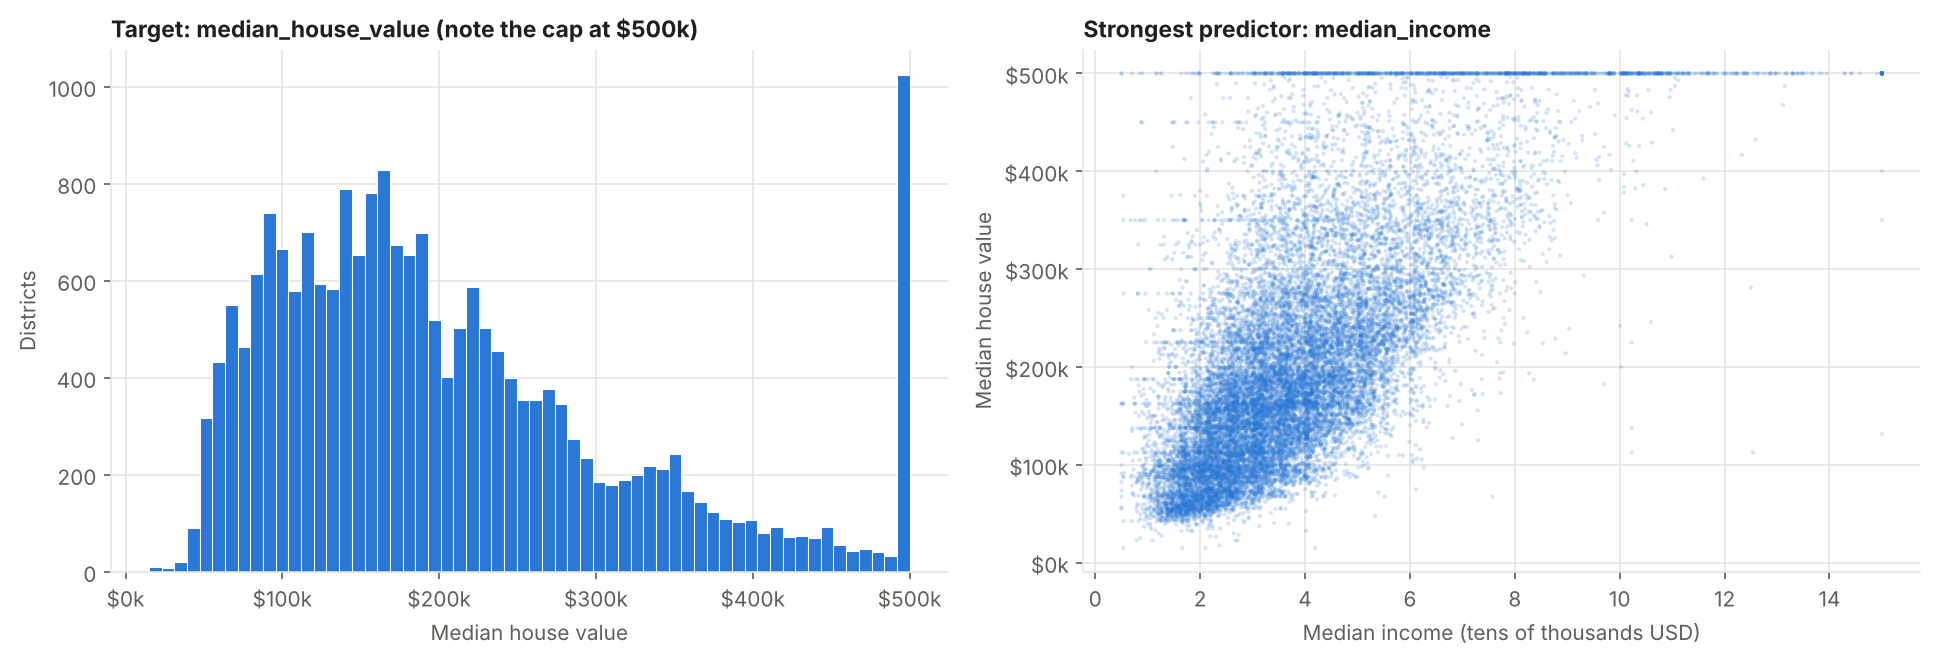

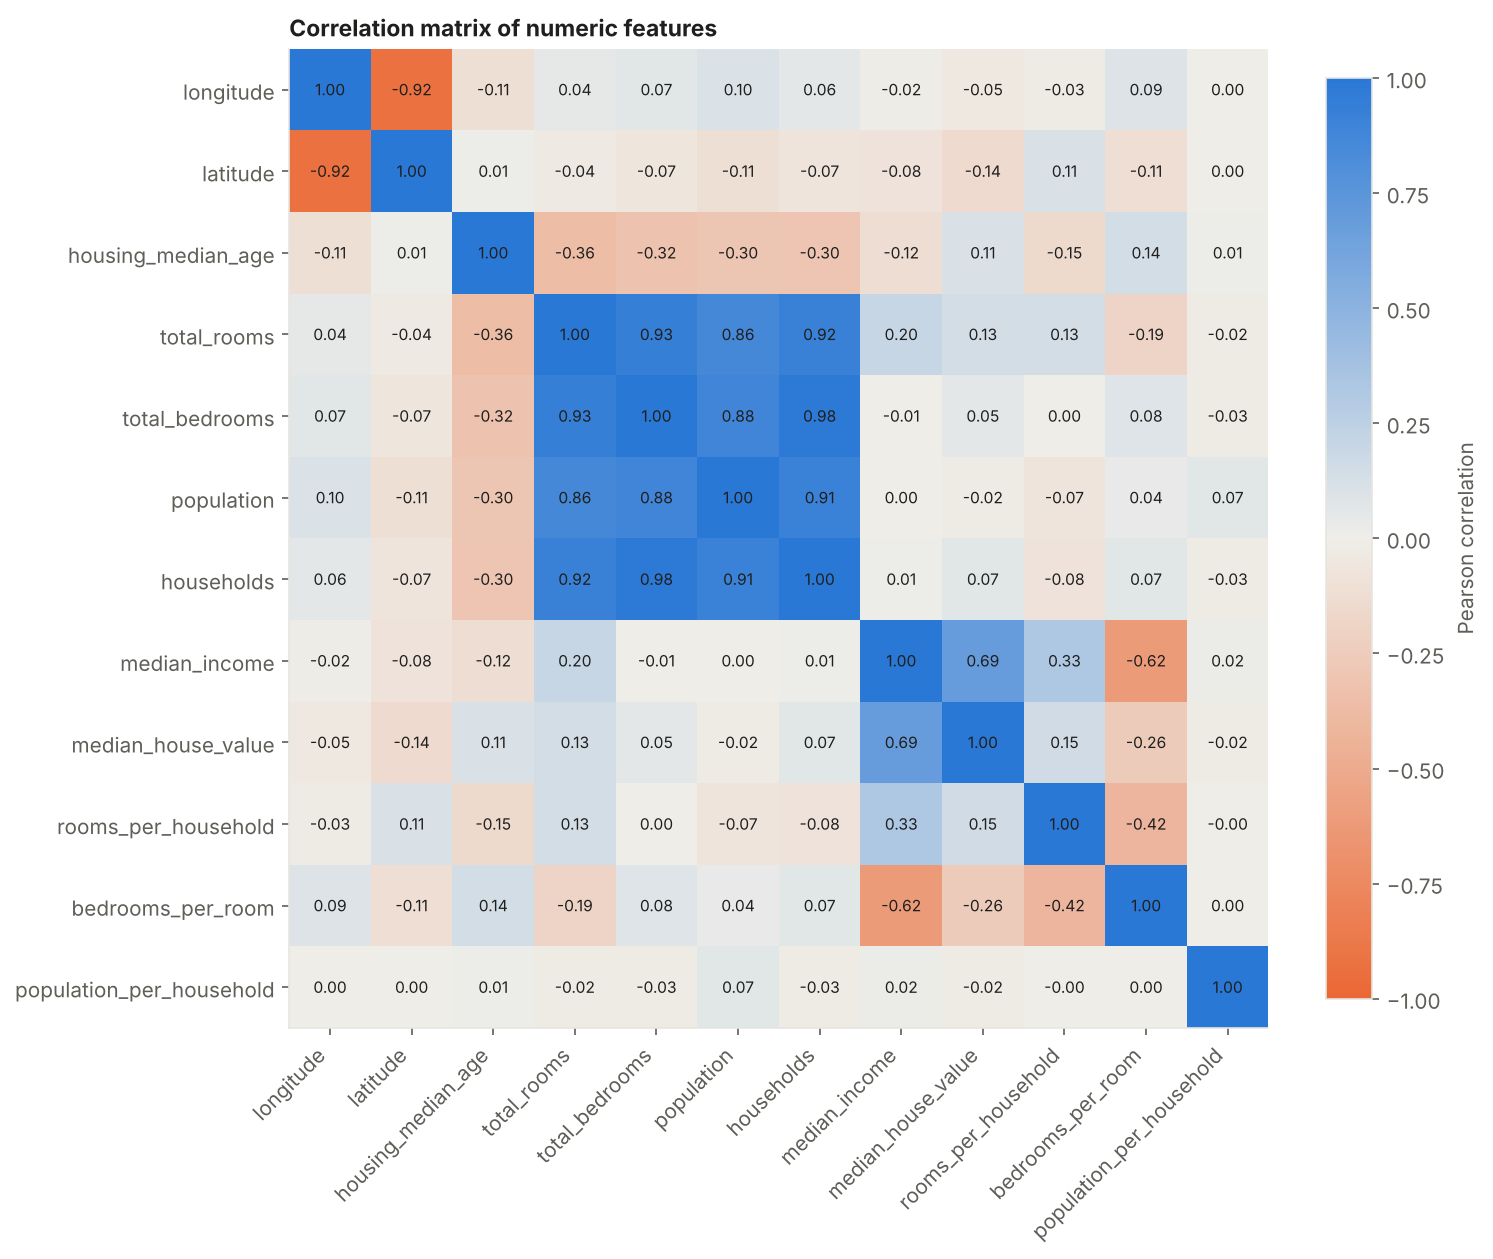

In [6]:
display(Image("results/figures/eda_target.png"))
display(Image("results/figures/eda_correlation.png"))

**Observations**
- 20,640 rows, 9 numeric features + 1 categorical (`ocean_proximity`).
- `total_bedrooms` has 207 missing values → median imputation.
- `median_income` is by far the most correlated feature with the target (≈ 0.69).
- The target is capped at \$500,001 (965 districts) — this limits every model at the top end.

## 2. Preprocessing & feature engineering
1. Add ratio features: `rooms_per_household`, `bedrooms_per_room`, `population_per_household`.
2. Split **80 % train / 20 % test** (`random_state=42`) — identical for all models.
3. Numeric features: median imputation → **StandardScaler** (z-score). Categorical: **one-hot encoding**.
4. Preprocessing is fitted on the training set only (inside a `Pipeline`) — no data leakage.

Scaling is essential for KNN (distances) and the Neural Network (gradient descent); it does not change tree-based models but keeps the pipeline identical for a fair comparison.

In [7]:
X_train, X_test, y_train, y_test = get_train_test()
print("Features used:", FEATURES)
print("Target:", TARGET)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

Features used: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity']
Target: median_house_value
Train: (16512, 12)  Test: (4128, 12)


In [8]:
pre = build_preprocessor().fit(X_train)
Xs = pre.transform(X_train)
print("Shape after preprocessing:", Xs.shape)
print("Means of scaled numeric columns (≈0):", np.round(Xs[:, :11].mean(0), 3))
print("Std  of scaled numeric columns (≈1):", np.round(Xs[:, :11].std(0), 3))

Shape after preprocessing: (16512, 16)
Means of scaled numeric columns (≈0): [ 0.  0. -0.  0. -0.  0. -0. -0.  0. -0.  0.]
Std  of scaled numeric columns (≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 3. Train the six models
k for KNN was chosen by 5-fold cross-validation on the training set (see `train.py`, figure below).

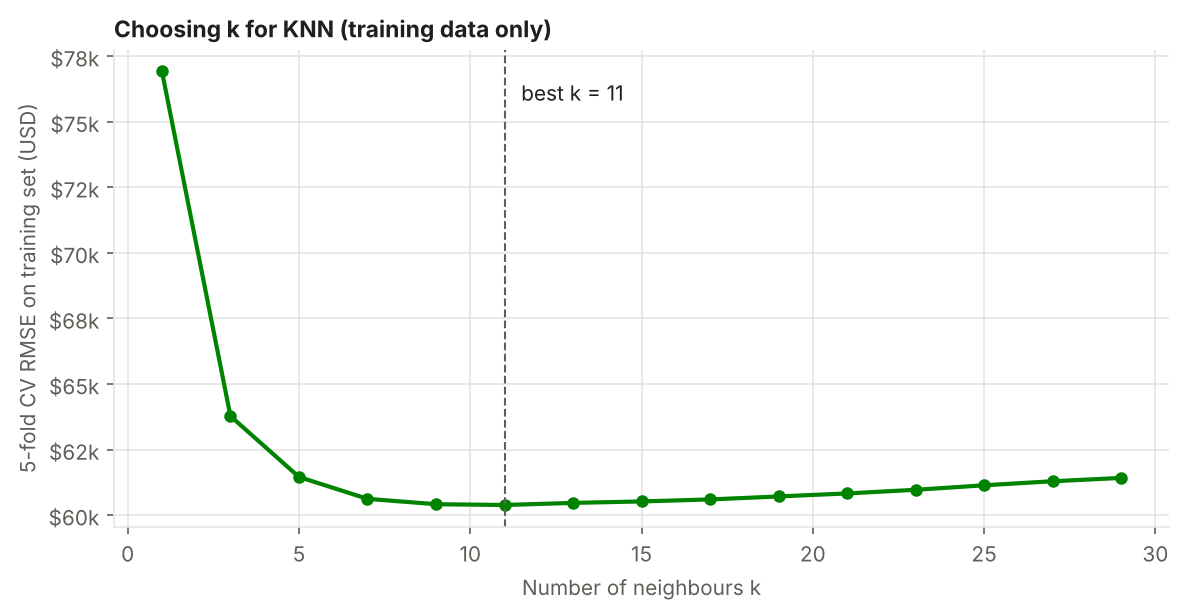

In [9]:
display(Image('results/figures/knn_k_selection.png'))

In [10]:
import json
best_k = json.load(open("results/summary.json"))["knn_best_k"]
pipelines = get_pipelines(knn_k=best_k)
for name, p in pipelines.items():
    print(f"{name:18s} ->", p.named_steps["model"])

Linear Regression  -> LinearRegression()
Decision Tree      -> DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=42)
Random Forest      -> RandomForestRegressor(max_features=0.5, min_samples_leaf=3, n_estimators=150,
                      n_jobs=-1, random_state=42)
Neural Network     -> TransformedTargetRegressor(regressor=MLPRegressor(alpha=0.001, batch_size=64,
                                                  early_stopping=True,
                                                  hidden_layer_sizes=(128, 64,
                                                                      32),
                                                  max_iter=300,
                                                  n_iter_no_change=20,
                                                  random_state=42),
                           transformer=StandardScaler())
XGBoost            -> XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample

In [11]:
results, preds = [], {}
for name, pipe in pipelines.items():
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    t = time.perf_counter() - t0
    y_pred = pipe.predict(X_test)
    preds[name] = y_pred
    m = regression_metrics(y_test, y_pred)
    m["Train R2"] = regression_metrics(y_train, pipe.predict(X_train))["R2"]
    results.append({"Model": name, **m, "Train time (s)": t})
    print(f"{name:18s} R2={m['R2']:.4f}  RMSE={m['RMSE']:,.0f}  MAE={m['MAE']:,.0f}  ({t:.1f}s)")

Linear Regression  R2=0.6353  RMSE=69,127  MAE=49,645  (0.0s)


Decision Tree      R2=0.7316  RMSE=59,306  MAE=38,874  (0.1s)


Random Forest      R2=0.8187  RMSE=48,739  MAE=31,628  (3.2s)


Neural Network     R2=0.7955  RMSE=51,761  MAE=34,739  (10.4s)


XGBoost            R2=0.8574  RMSE=43,228  MAE=28,009  (1.6s)


KNN                R2=0.7207  RMSE=60,502  MAE=40,279  (0.0s)


### Learned parameters (examples)

In [12]:
lr = pipelines["Linear Regression"]
names = [n.split("__",1)[1] for n in lr.named_steps["preprocess"].get_feature_names_out()]
coef = pd.Series(lr.named_steps["model"].coef_, index=names).sort_values()
print("Intercept:", round(lr.named_steps["model"].intercept_, 2))
coef.to_frame("coefficient (per 1 std of feature)")

Intercept: 237125.78


,coefficient (per 1 std of feature)
latitude,"-56,638.2312"
longitude,"-56,276.0589"
ocean_proximity_INLAND,"-53,617.8404"
population,"-46,320.2855"
ocean_proximity_NEAR BAY,"-24,109.1851"
ocean_proximity_<1H OCEAN,"-18,666.4786"
ocean_proximity_NEAR OCEAN,"-15,666.7404"
population_per_household,750.3679
total_bedrooms,"5,307.6630"
total_rooms,"5,881.1050"


In [13]:
dt = pipelines["Decision Tree"].named_steps["model"]
print("Decision tree depth:", dt.get_depth(), " leaves:", dt.get_n_leaves())
nn = pipelines["Neural Network"].named_steps["model"].regressor_
print("MLP layers:", [w.shape for w in nn.coefs_], " epochs run:", nn.n_iter_)
xgb = pipelines["XGBoost"].named_steps["model"]
print("XGBoost trees:", xgb.n_estimators)

Decision tree depth: 12  leaves: 759
MLP layers: [(16, 128), (128, 64), (64, 32), (32, 1)]  epochs run: 84
XGBoost trees: 800


## 4. Comparative performance table

In [14]:
table = pd.DataFrame(results).set_index("Model").sort_values("RMSE")
table.insert(0, "Rank", range(1, len(table) + 1))
table

,Rank,MAE,MSE,RMSE,R2,Train R2,Train time (s)
Model,,,,,,,
XGBoost,1,"28,009.2653","1,868,654,925.1234","43,227.9415",0.8574,0.9806,1.6215
Random Forest,2,"31,627.9202","2,375,488,319.7889","48,738.9815",0.8187,0.9402,3.2282
Neural Network,3,"34,738.8395","2,679,186,512.8758","51,760.8589",0.7955,0.8630,10.3767
Decision Tree,4,"38,874.0053","3,517,146,190.2983","59,305.5325",0.7316,0.8470,0.1457
KNN,5,"40,278.7082","3,660,510,176.0357","60,502.1502",0.7207,1.0000,0.0178
Linear Regression,6,"49,645.4924","4,778,547,424.0260","69,127.0383",0.6353,0.6582,0.0221


In [15]:
cv = pd.read_csv("results/metrics.csv", index_col=0)[["CV RMSE (mean)", "CV RMSE (std)"]]
print("5-fold cross-validated RMSE on the training set (robustness check):")
cv.loc[table.index]

5-fold cross-validated RMSE on the training set (robustness check):


,CV RMSE (mean),CV RMSE (std)
Model,,
XGBoost,"44,669.4647",779.9572
Random Forest,"49,430.6445","1,042.0674"
Neural Network,"52,357.6586","1,142.2912"
Decision Tree,"59,066.4749","1,027.6445"
KNN,"60,387.8591","1,077.4724"
Linear Regression,"67,858.7785","1,312.1723"


## 5. Visualisations

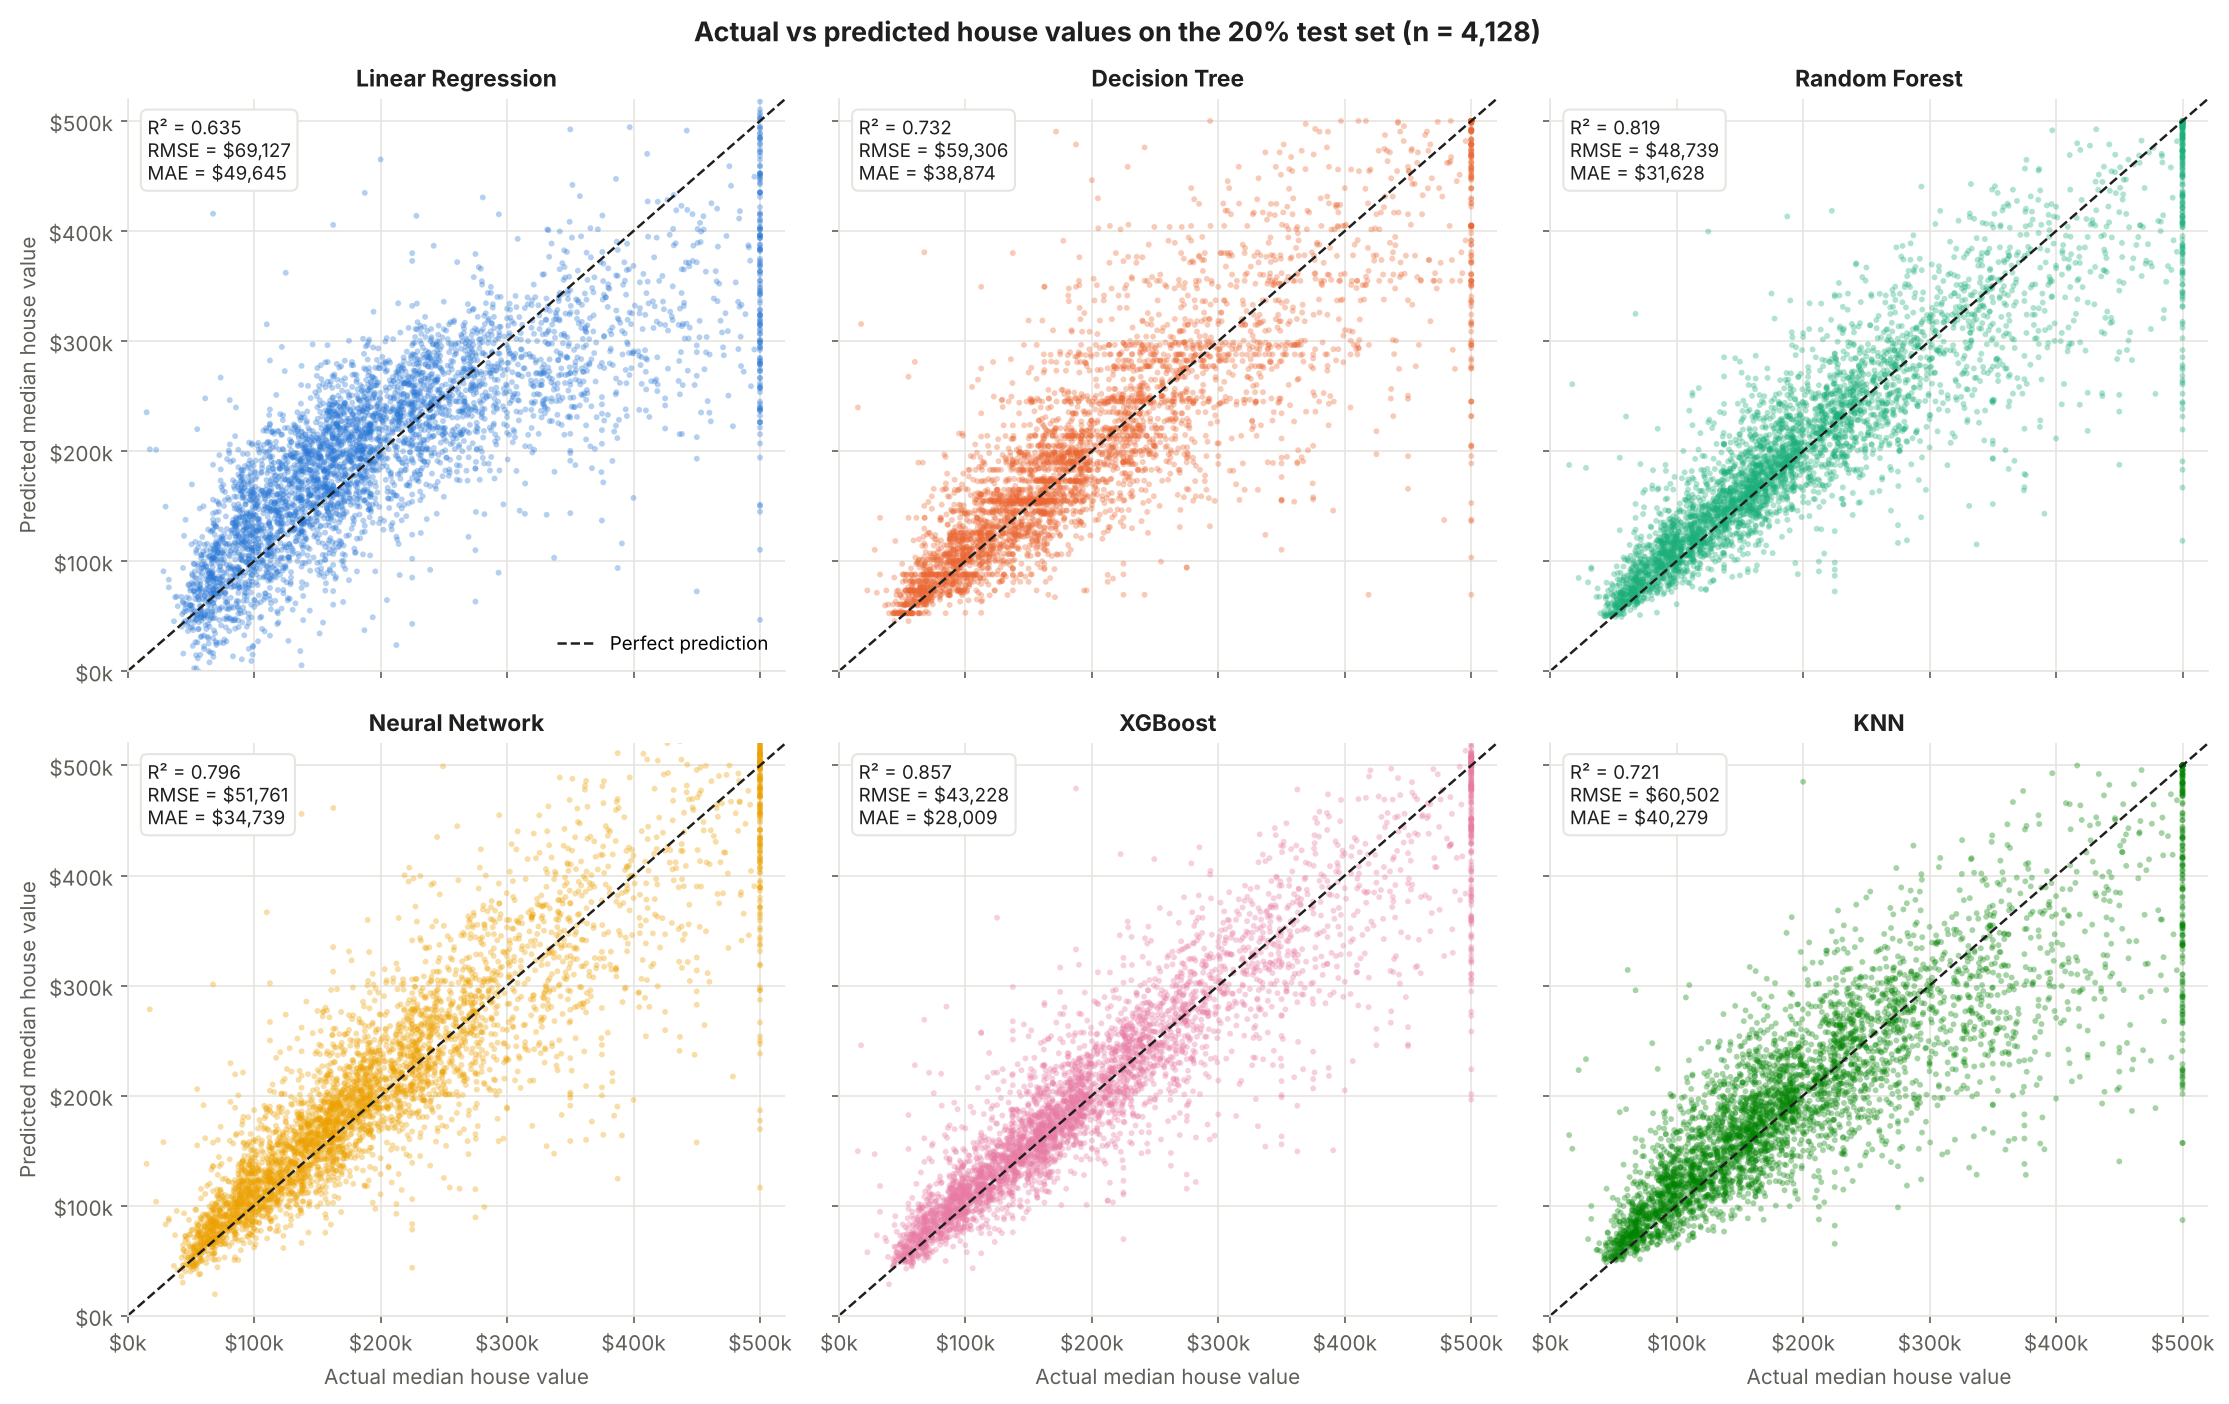

In [16]:
display(Image('results/figures/actual_vs_predicted.png'))

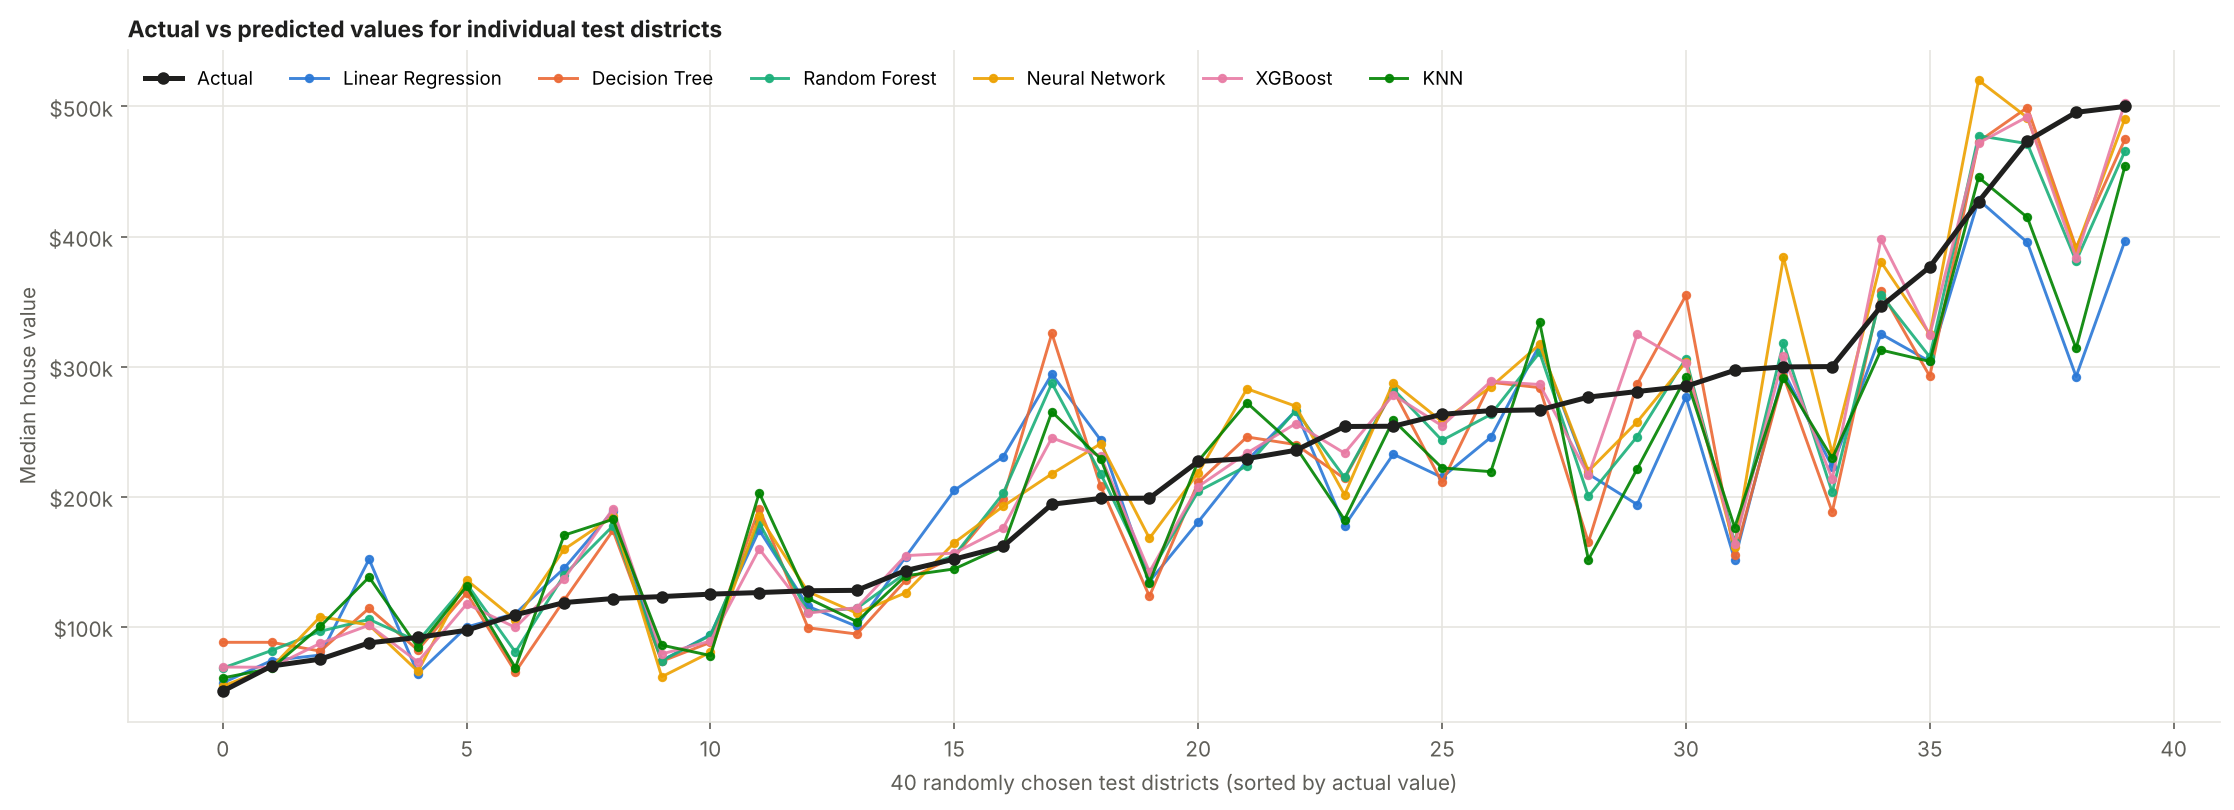

In [17]:
display(Image('results/figures/sample_predictions.png'))

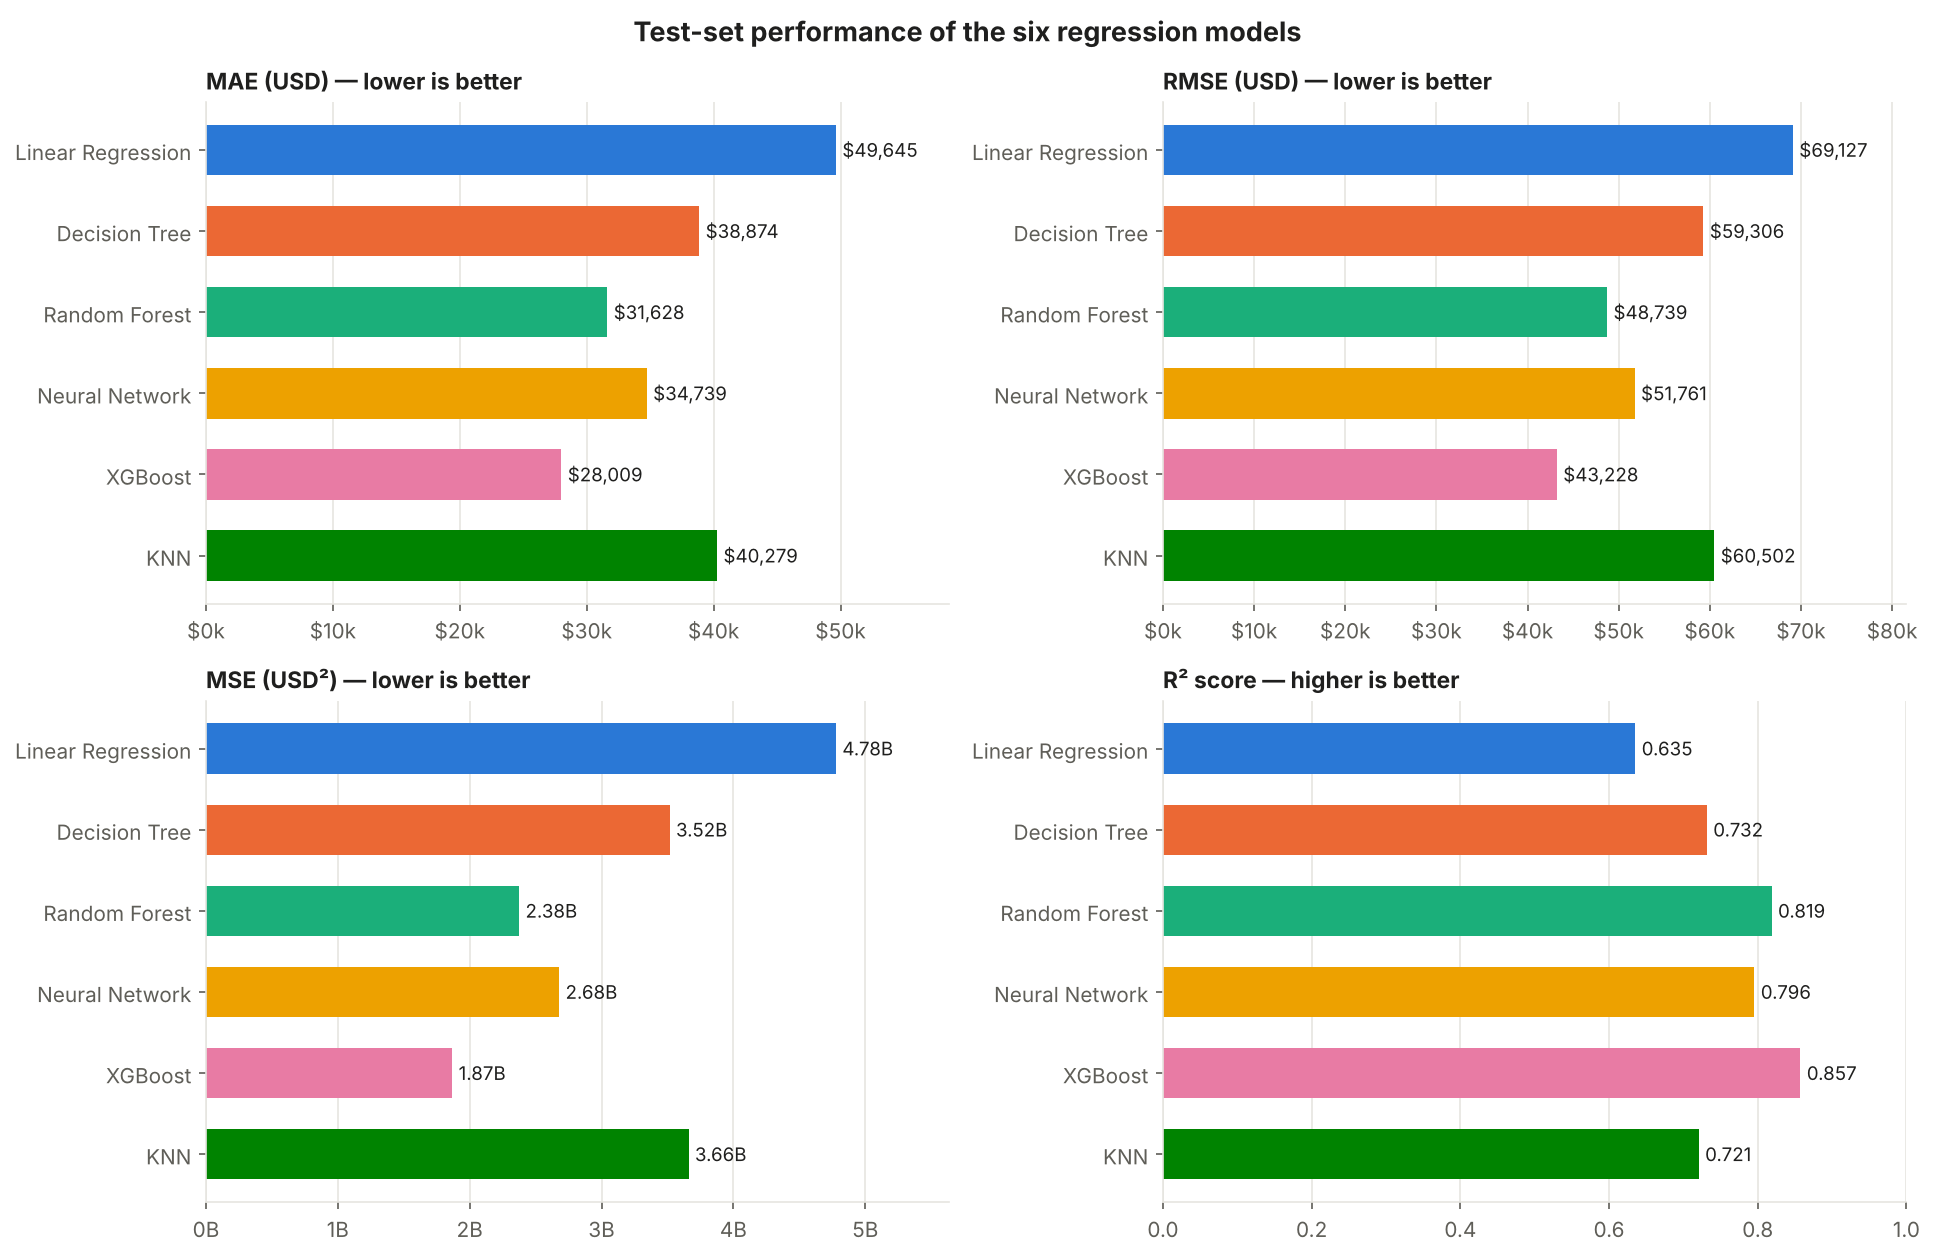

In [18]:
display(Image('results/figures/metrics_comparison.png'))

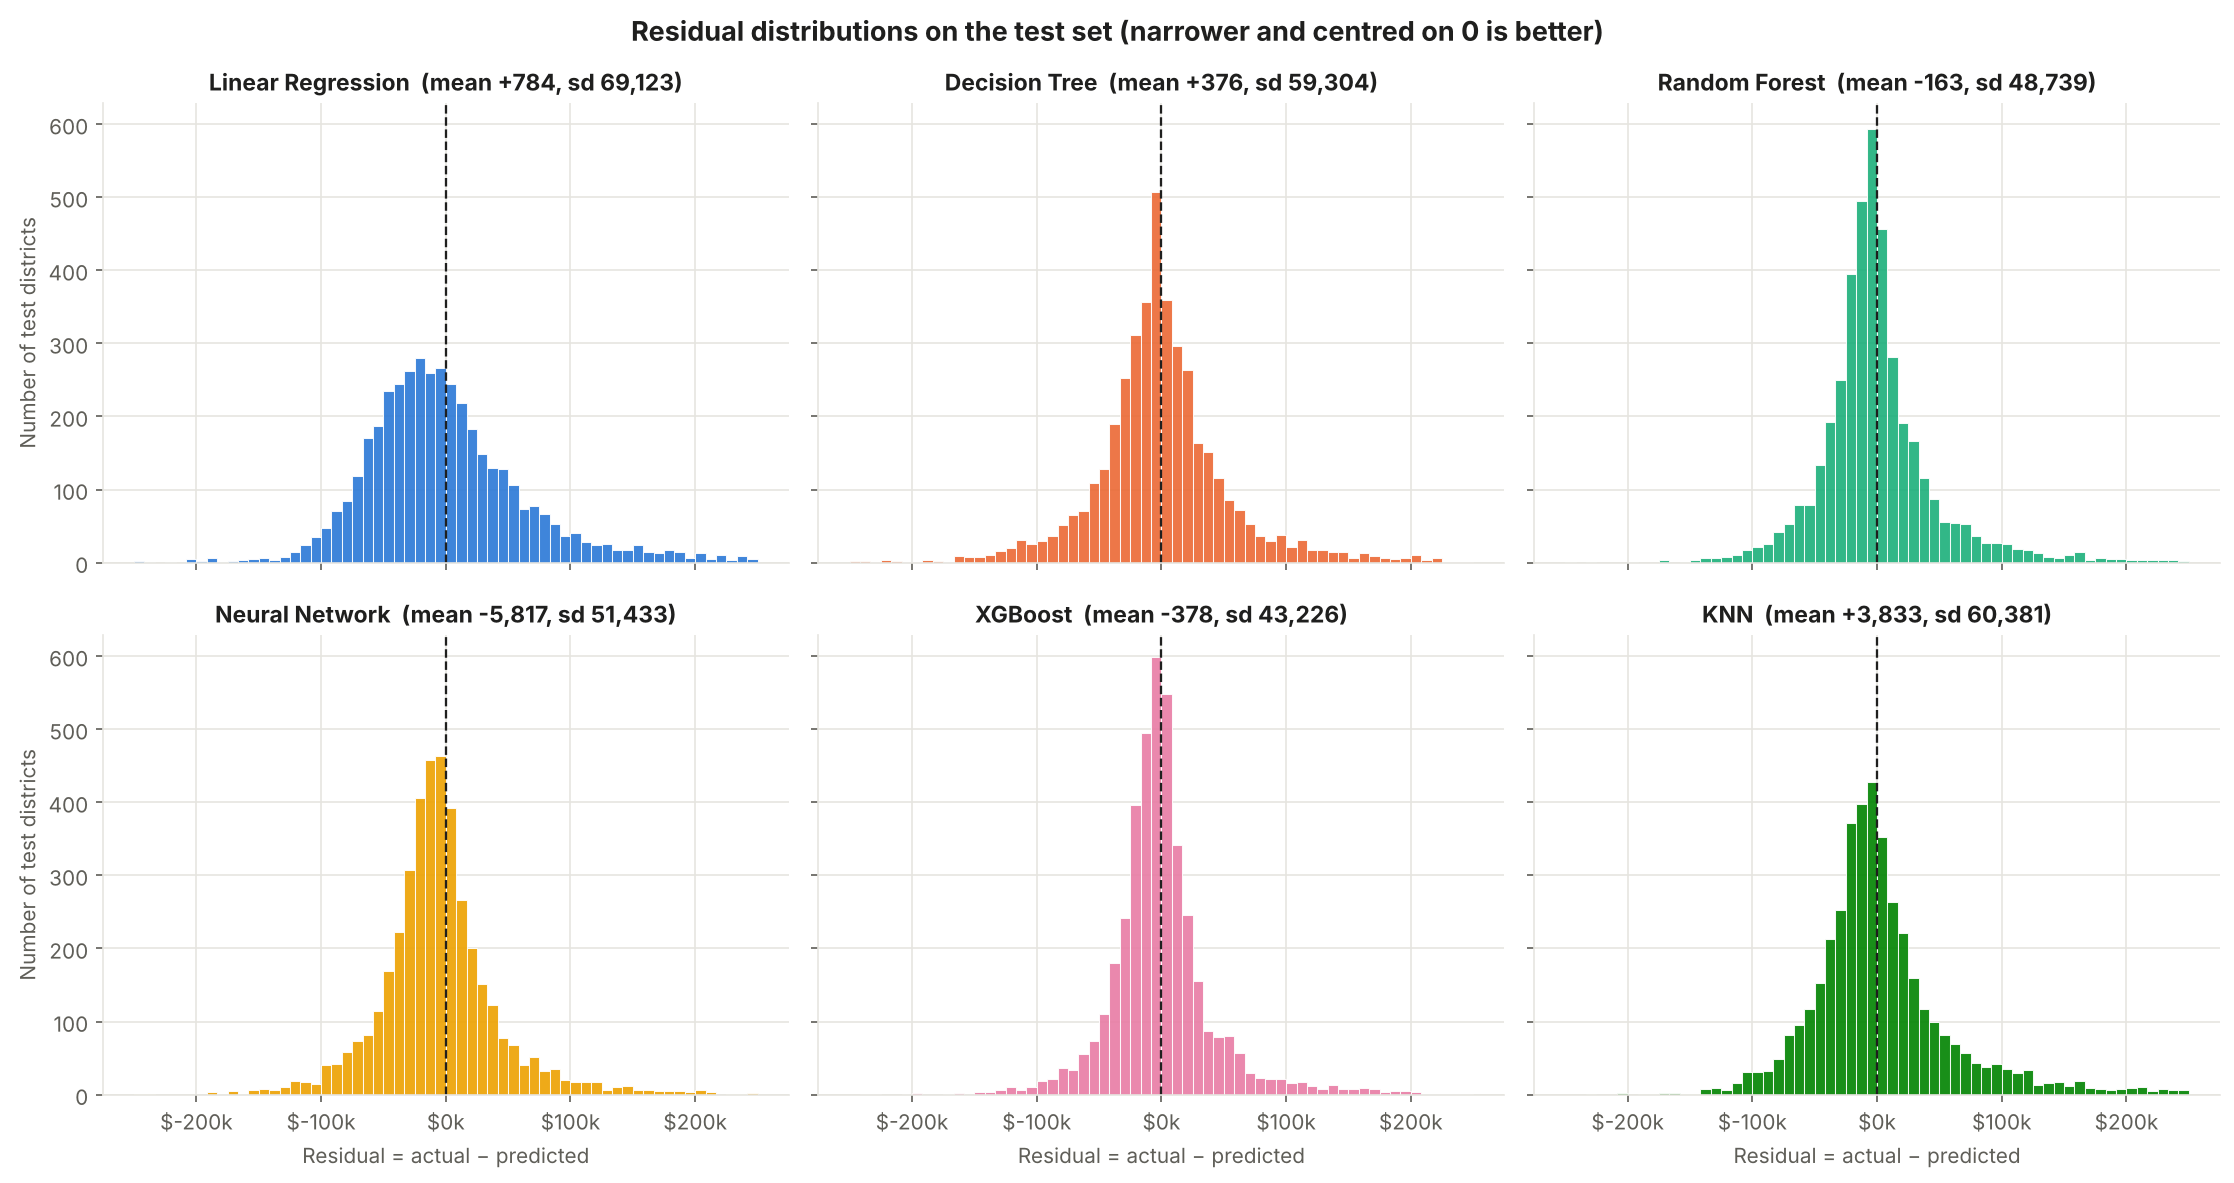

In [19]:
display(Image('results/figures/residuals.png'))

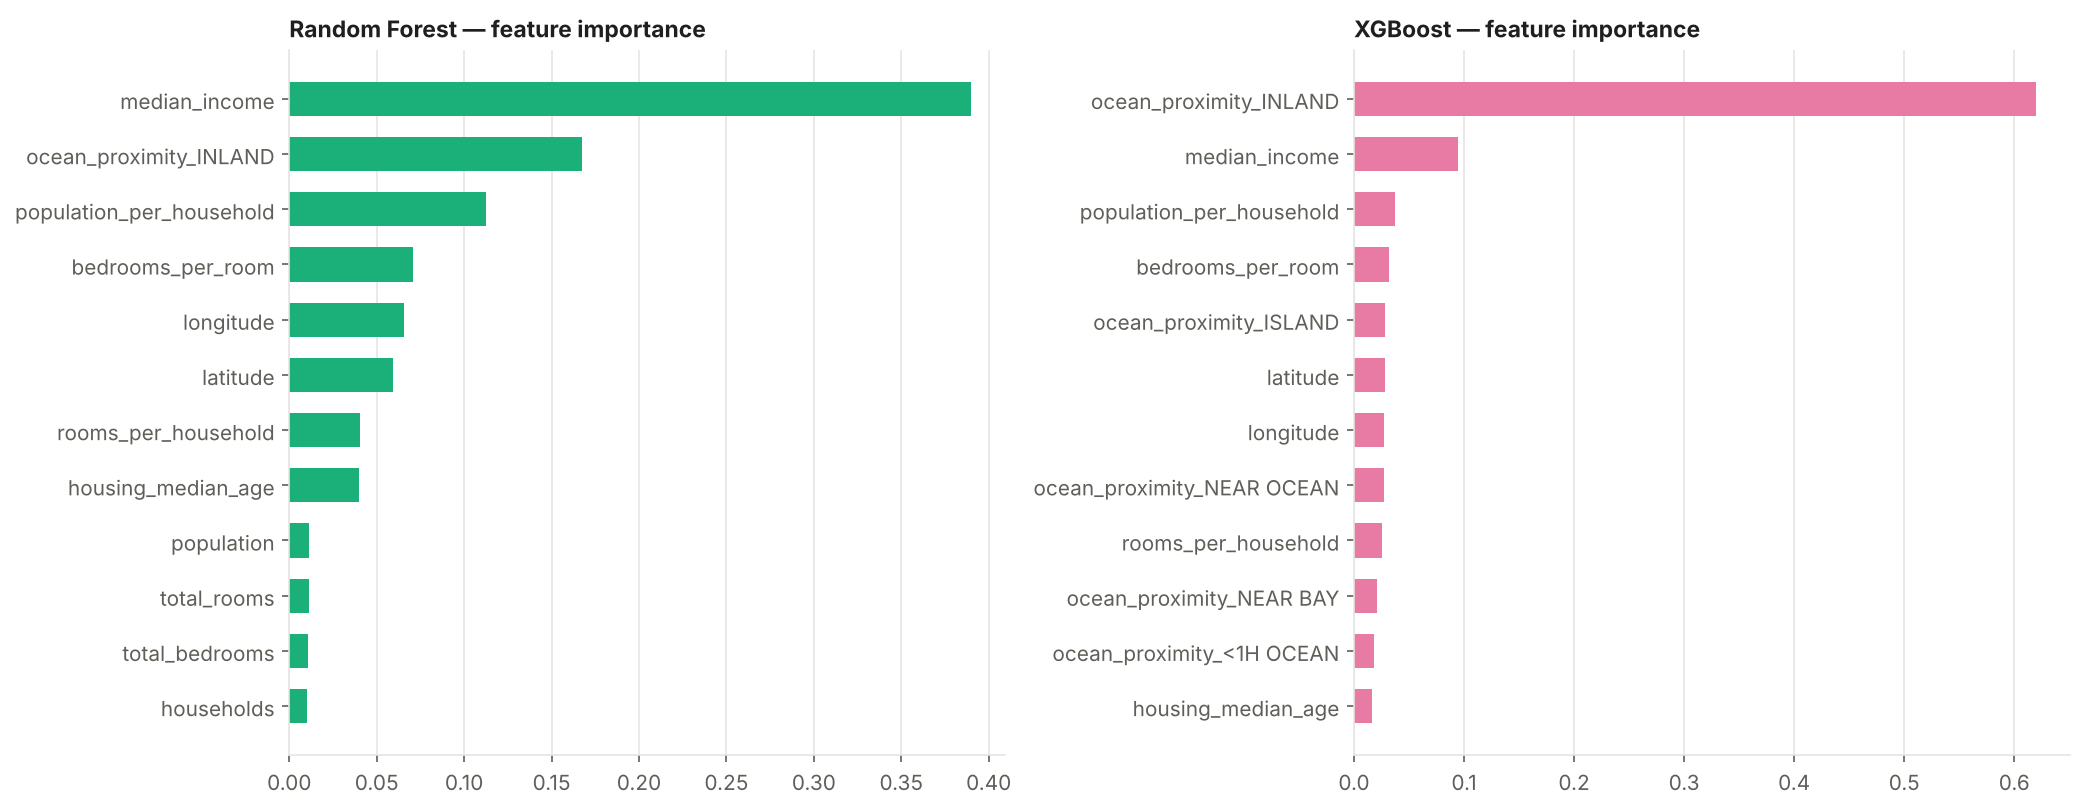

In [20]:
display(Image('results/figures/feature_importance.png'))

## 6. Strengths and limitations

| Algorithm | Strengths | Limitations |
|---|---|---|
| **Linear Regression** | Fast, interpretable coefficients, no tuning, good baseline | Assumes linear relationships; underfits (train R² ≈ test R² ≈ 0.64); sensitive to outliers & multicollinearity |
| **Decision Tree** | Captures non-linearity & interactions, no scaling needed, easy to visualise | High variance — small data changes give a different tree; piece-wise constant predictions (visible as horizontal bands) |
| **Random Forest** | Averaging many decorrelated trees greatly reduces variance; robust; feature importance | Large model (≈18 MB), slower predictions, less interpretable, cannot extrapolate beyond training range |
| **Neural Network** | Learns complex non-linear functions; flexible | Needs scaling & tuning, slower to train, black box, results depend on random initialisation |
| **XGBoost** | Sequential error-correcting trees + L2 regularisation + shrinkage → best accuracy; fast `hist` algorithm; handles missing values | Many hyper-parameters; can overfit (train R² 0.98) without regularisation/early stopping; less interpretable |
| **KNN** | Simple, no training, naturally non-linear | Must scale features; slow prediction on large data; suffers from curse of dimensionality; memorises training set (train R² = 1.0 with distance weights) |

In [21]:
best = table.index[0]
r = table.loc[best]
print(f"Best model: {best}")
print(f"  R2   = {r.R2:.4f}  (explains {r.R2*100:.1f}% of the variance of house prices)")
print(f"  RMSE = ${r.RMSE:,.0f}   MAE = ${r.MAE:,.0f}")
second = table.index[1]
print(f"  RMSE is {100*(1 - r.RMSE/table.loc[second,'RMSE']):.1f}% lower than the runner-up ({second})")
print(f"  RMSE is {100*(1 - r.RMSE/table.loc['Linear Regression','RMSE']):.1f}% lower than Linear Regression")

Best model: XGBoost
  R2   = 0.8574  (explains 85.7% of the variance of house prices)
  RMSE = $43,228   MAE = $28,009
  RMSE is 11.3% lower than the runner-up (Random Forest)
  RMSE is 37.5% lower than Linear Regression


## 7. Conclusion
**XGBoost is the best-performing algorithm** — it has the lowest MAE, MSE and RMSE and the highest R² on the test set, and also the lowest 5-fold cross-validated RMSE, so the result is not due to a lucky split.

Why: house prices depend non-linearly on income and location and on interactions between them (e.g. inland vs coastal). Boosting builds trees sequentially, each one fitting the residual errors of the previous trees, while L2 regularisation (λ), shrinkage (η = 0.05), row/column subsampling keep it from overfitting. Random Forest (bagging) is second, the Neural Network third; single Decision Tree and KNN are clearly weaker, and Linear Regression underfits because it can only draw a flat hyperplane.